The purpose of this notebook is to generate the following plots. 
-Full page: 9 plots of the temp measurements for PC1. Include peak with uncertainty and peak width with uncertainty.
-Same with 8 plots for PC2.
-One Diagramm showing the T-max dependence with plots for PC1 and PC2 and three lines... one using the data from only one PC, one with both overlapping. 

-All fits should use the Amplitude against the frequency, taking care to also treat the amplitude errors dA correctly. 
-Fits should use a Lorentz Resonance curve with f_0/sqrt((w_0-w)^2+gamma^2*w^2) (where w stands in for an omega). Underneath the fits, display the peak frequency w_0 with an appropriate error/uncertaints. Also calculate the Güte Q=omega_0/gamma. Display Güte, Dämpfung and Resonanzfrequenz with uncertainties in text underneath each graphs
-for the graphs, only display the data between 248.5 and 251.5 Hz.
-Do all the descriptions in German. 
-ALso do a chi_2 calculation for each graph and give the corresponding value. 

## Temperaturabhängigkeit der Resonanz
Neun Messungen von PC1, acht von PC2 und ein gemeinsames Temperaturdiagramm. Alle Beschriftungen und Auswertungen sind auf Deutsch.
Modell und Annahmen. Die Aufgabenformel enthält vermutlich einen Schreibfehler: Für einen gedämpften Oszillator und die angegebene Güte $Q=\omega_0/\gamma$ wird hier die dimensionskonsistente Amplitudenresonanz
$A(\omega)=\frac{C}{\sqrt{(\omega_0^2-\omega^2)^2+\gamma^2\omega^2}},\qquad \omega=2\pi f$
verwendet (also quadratische Frequenzen im ersten Differenzterm). $\omega_0$ ist die Eigenkreisfrequenz; das Amplitudenmaximum liegt bei $\omega_\mathrm{max}=\sqrt{\omega_0^2-\gamma^2/2}$. Beide werden angegeben. Die Peakbreite ist die volle Breite bei halber Amplitude (FWHM), nicht die Halbwertsbreite der Leistung.
Fit und Darstellung verwenden ausschließlich 248,5–251,5 Hz. Die unabhängigen gaußförmigen Amplitudenfehler dA gehen als absolute Standardabweichungen in die gewichteten Fits ein; die Kovarianz wird nicht mit dem reduzierten $\chi^2$ nachskaliert. Abgeleitete Unsicherheiten berücksichtigen die vollständige Parameterkovarianz (lineare Fehlerfortpflanzung, $1\sigma$). Große $\chi^2_\mathrm{red}$ zeigen Modellabweichungen bzw. nicht ausreichend beschriebene Messfehler; dann sind die formalen Fitfehler entsprechend vorsichtig zu interpretieren.
„T-max-Abhängigkeit“ wird als Frequenz des Amplitudenmaximums gegen Temperatur verstanden. Die drei Geraden verwenden PC1, PC2 und beide Messreihen gemeinsam. Datenbefund: Bei PC2 liegt die angepasste Breite außerhalb des schmalen Fensters; bei PC1/48 ist sie kleiner als der Frequenzabstand. Diese Fits sind nicht belastbar aufgelöst. Sternchen kennzeichnen solche Fälle. Die Temperaturgeraden enthalten wie angefordert alle Messungen und sind daher nur explorativ; ihre formalen Fehler erfassen diese Modellunsicherheit nicht. Für eine belastbare Auswertung sind ein breiteres Fitfenster (PC2) bzw. feinere Frequenzschritte (PC1/48) erforderlich. Temperatur: Mittelwert von T_set im Fitfenster (angenommen in °C); die horizontale Fehlerleiste zeigt die Streuung der Messwerte, keinen kalibrierten Temperaturfehler. Mangels Temperatur- und Frequenzkalibrierfehlern berücksichtigen die Geraden nur die Unsicherheit von $f_\mathrm{max}$.
Benötigt: numpy, pandas, scipy, matplotlib. Die fünf Codezellen der Reihe nach ausführen. Das Notebook im Projektordner oder in Code/ ablegen; andernfalls PROJEKT in Zelle 1 setzen.

In [35]:

from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.style.use("default")

from scipy.optimize import curve_fit
from IPython.display import display

# Optional den Projektordner explizit setzen, falls der Kernel anderswo startet.
PROJEKT = None
if PROJEKT is None:
    kandidaten = [Path.cwd(), *Path.cwd().parents]
    PROJEKT = next((p for p in kandidaten if (p / "important_data").is_dir()), None)
    if PROJEKT is None:
        raise FileNotFoundError("PROJEKT auf den Ordner mit important_data setzen.")
PROJEKT = Path(PROJEKT)
F_MIN, F_MAX = 200.5, 400.5
quellen = {
    "PC1": (Path("important_data/PC1/PC1_final_WithTemp"),
            [f"TempFreq{t}.csv" for t in [40, 42, 44, 46, 48, 50, 52, 54, 58]]),
    "PC2": (Path("important_data/PC2/WithTemp"),
            [f"final_TempFreq{t:.1f}.csv" for t in [37, 40, 43, 46, 49, 52, 55, 58]])
}
plt.rcParams.update({"font.size": 9, "axes.grid": True, "grid.alpha": 0.2,
                     "figure.dpi": 120, "savefig.dpi": 180})
messungen = [] #is a list
for pc, (ordner, namen) in quellen.items():
    for name in namen:
        pfad = PROJEKT / ordner / name
        df = pd.read_csv(pfad)
        spalten = ["FQ", "A", "dA", "T_set"]
        if not set(spalten).issubset(df.columns):
            raise ValueError(f"{name}: Benötigte Spalten fehlen.")
        df = df[spalten].apply(pd.to_numeric, errors="coerce")
        fenster = df.loc[df.FQ.between(F_MIN, F_MAX)].copy()
        gueltig = np.isfinite(fenster).all(axis=1) & (fenster.dA > 0)
        if (~gueltig).any():
            warnings.warn(f"{name}: {(~gueltig).sum()} ungültige Zeilen ausgeschlossen.")
        fenster = fenster.loc[gueltig].sort_values("FQ")
        if len(fenster) <= 3 or fenster.FQ.nunique() <= 3:
            raise ValueError(f"{name}: Zu wenige gültige Frequenzen im Fitfenster.")
        messungen.append({"PC": pc, "Datei": name, "daten": fenster,
                          "T": fenster.T_set.mean(), "sT": fenster.T_set.std(ddof=1)})
print(f"{len(messungen)} Messungen geladen (PC1: 9, PC2: 8).")

17 Messungen geladen (PC1: 9, PC2: 8).


/var/folders/gh/zgcw3f1x0_96gs469254kk3r0000gn/T/ipykernel_49890/870323617.py:40: UserWarning: final_TempFreq37.0.csv: 8 ungültige Zeilen ausgeschlossen.
  warnings.warn(f"{name}: {(~gueltig).sum()} ungültige Zeilen ausgeschlossen.")
/var/folders/gh/zgcw3f1x0_96gs469254kk3r0000gn/T/ipykernel_49890/870323617.py:40: UserWarning: final_TempFreq40.0.csv: 7 ungültige Zeilen ausgeschlossen.
  warnings.warn(f"{name}: {(~gueltig).sum()} ungültige Zeilen ausgeschlossen.")
/var/folders/gh/zgcw3f1x0_96gs469254kk3r0000gn/T/ipykernel_49890/870323617.py:40: UserWarning: final_TempFreq43.0.csv: 7 ungültige Zeilen ausgeschlossen.
  warnings.warn(f"{name}: {(~gueltig).sum()} ungültige Zeilen ausgeschlossen.")
/var/folders/gh/zgcw3f1x0_96gs469254kk3r0000gn/T/ipykernel_49890/870323617.py:40: UserWarning: final_TempFreq46.0.csv: 6 ungültige Zeilen ausgeschlossen.
  warnings.warn(f"{name}: {(~gueltig).sum()} ungültige Zeilen ausgeschlossen.")
/var/folders/gh/zgcw3f1x0_96gs469254kk3r0000gn/T/ipykernel_49890

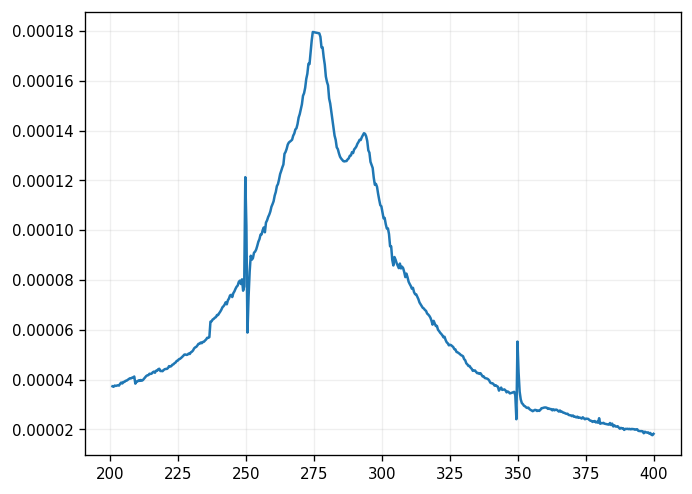

In [36]:
#tests
#PC1=messungen[14]["daten"]
#fq=PC1.FQ.to_numpy()
#amp=PC1.A.to_numpy()
#PC1: 245 - 255 reasonable
#Für Fit: Mitte ev. rausnehmen. 

plt.plot(fq,amp)

### Resonanzfits und Fehlerfortpflanzung
Numerisch wird in Hz gerechnet: $f_0=\omega_0/(2\pi)$ und $g=\gamma/(2\pi)$. Der Skalierungsparameter $H$ entspricht der Amplitude bei $f_0$.

In [37]:
def resonanz(f, H, f0, g,b):
    # Gleichwertig zum oben angegebenen Oszillatormodell; H hat Amplitudeneinheiten.
    return H * g * f0 / np.sqrt((f0**2 - f**2)**2 + (g*f)**2)+b

def kenngroessen(p):
    H, f0, g, b = p
    fmax = np.sqrt(f0**2 - g**2/2)
    dmin = g**2*f0**2 - g**4/4
    # Exakte Lösungen für A(f) = A(fmax)/2.
    wurzel = np.sqrt(3*dmin)
    breite = np.sqrt(fmax**2 + wurzel) - np.sqrt(fmax**2 - wurzel)
    return np.array([f0, 2*np.pi*f0, fmax, breite, 2*np.pi*g, f0/g,b])

def fortpflanzung(p, kov):
    schritte = np.maximum(
        np.abs(p)*1e-5,
        [1e-8, 1e-6, 1e-7, 1e-8]
    )

    jac = np.column_stack([
        (kenngroessen(p + np.eye(4)[i]*h)
         - kenngroessen(p - np.eye(4)[i]*h))/(2*h)
        for i, h in enumerate(schritte)
    ])

    return np.sqrt(np.maximum(np.diag(jac @ kov @ jac.T), 0))

def wert(v, dv, einheit=""):
    # Zwei signifikante Stellen im Fehler; Wert auf dieselbe Dezimalstelle runden.
    stellen = 1 - int(np.floor(np.log10(dv))) if dv > 0 else 4
    v, dv = round(float(v), stellen), round(float(dv), stellen)
    dez = max(0, stellen)
    return (f"{v:.{dez}f} ± {dv:.{dez}f} {einheit}").strip()


In [38]:
F_MIN = 248
F_MAX = 252.2

messungen_fit = [m.copy() for m in messungen]
namen = ["f0", "omega0", "fmax", "breite", "gamma", "Q", "b"]

for m in messungen_fit[0:9]:
    d = m["daten"]

    # Nur Messpunkte innerhalb des Fitbereichs verwenden
    maske = (d.FQ >= F_MIN) & (d.FQ <= F_MAX)
    f = d.loc[maske, "FQ"].to_numpy()
    a = d.loc[maske, "A"].to_numpy()
    da = d.loc[maske, "dA"].to_numpy()


    # Temperaturstatistik ausschließlich aus den
    # Messpunkten, die auch für den Resonanzfit verwendet werden
    T_fit = d.loc[maske, "T_set"].to_numpy()

    m["T"] = float(np.mean(T_fit))
    m["sT"] = float(np.std(T_fit, ddof=1))

    # Solltemperatur aus dem Dateinamen, z.B. TempFreq54.csv
    m["T_soll"] = float(
        Path(m["Datei"]).stem.split("TempFreq")[-1]
    )


    if len(np.unique(f)) < 5:
        raise ValueError("Zu wenige unterschiedliche Frequenzen für den Fit.")
    if not (np.isfinite(f).all() and np.isfinite(a).all()
            and np.isfinite(da).all() and np.all(da > 0)):
        raise ValueError("Ungültige Messwerte oder Unsicherheiten.")

    # Amplitudenskalierung verbessert die numerische Kondition
    skala = np.max(np.abs(a))
    if skala <= 0:
        raise ValueError(f"{m['Datei']}: Keine von null verschiedene Amplitude.")

    start_f = float(f[np.argmax(a)])
    kandidaten = []

    for start_g in [0.03, 0.1, 0.3, 1.0]:
        try:
            p_norm, kov_norm = curve_fit(
                resonanz, f, a/skala,
                sigma=da/skala,
                absolute_sigma=True,
                p0=[1, start_f, start_g, -0.2],
                bounds=([0, F_MIN, 1e-5, -np.inf],
                        [1.5, F_MAX, 10, np.inf]),
                x_scale="jac",
                max_nfev=20000,
                ftol=1e-11, xtol=1e-11, gtol=1e-11
            )

            # Chi² mit korrekt skalierter Modellfunktion
            chi2 = float(np.sum(
                ((a/skala - resonanz(f, *p_norm))/(da/skala))**2
            ))
            kandidaten.append((chi2, p_norm, kov_norm))

        except (RuntimeError, ValueError):
            continue

    if not kandidaten:
        raise RuntimeError(f"{m['Datei']}: Kein Fit konvergiert.")

    chi2, p, kov = min(kandidaten, key=lambda item: item[0])
    



    m.update(
        p=p,
        kov=kov,
        skala=skala,
        chi2=chi2,
        ndf=len(f)-4
    )

    m.update(zip(namen, kenngroessen(p)))
    m.update(zip(["d" + n for n in namen], fortpflanzung(p, kov)))

    abstand = np.median(np.diff(np.unique(f)))

    m["eingeschraenkt"] = bool(
        not np.isfinite(m["breite"])
        or m["breite"] < abstand
        or m["breite"] > F_MAX-F_MIN
        or p[2] > 9.99
        or min(p[1]-F_MIN, F_MAX-p[1]) < 1e-4
    )

print("Nur eingeschränkt bestimmte Resonanzparameter:")

for m in messungen_fit[0:9]:
    if m["eingeschraenkt"]:
        print(f"  {m['PC']}: {m['Datei']}")

Nur eingeschränkt bestimmte Resonanzparameter:


In [39]:

from scipy.optimize import least_squares
from scipy import stats

T_REF = 50.0  # Bezugstemperatur in °C


def temperaturfit(gruppe):
    # Gemessene Temperaturmittelwerte
    T = np.array([m["T"] for m in gruppe], dtype=float)

    # Resonanzfrequenzen und ihre Fitunsicherheiten
    y = np.array([m["f0"] for m in gruppe], dtype=float)
    sy = np.array([m["df0"] for m in gruppe], dtype=float)

    # Gemessene Temperaturstandardabweichungen
    # (nicht Standardfehler des Mittelwerts)
    sx = np.array([m["sT"] for m in gruppe], dtype=float)

    x = T - T_REF

    if not (
        np.isfinite(T).all()
        and np.isfinite(y).all()
        and np.isfinite(sx).all()
        and np.isfinite(sy).all()
    ):
        raise ValueError("Temperaturdaten oder Fehler enthalten NaN/Inf.")

    if np.any(sy <= 0) or np.any(sx < 0):
        raise ValueError("Ungültige Messunsicherheiten.")

    # Effektive Varianz unter Berücksichtigung
    # beider Messunsicherheiten
    def residual(parameter):
        a, c = parameter
        return (y - a*x - c) / np.sqrt(
            sy**2 + a**2*sx**2
        )

    # Mehrere Startwerte, da die Varianz
    # von der gesuchten Steigung abhängt
    fits = [
        least_squares(
            residual, [a0, np.mean(y)],
            ftol=1e-12,
            xtol=1e-12,
            gtol=1e-12,
            max_nfev=20000
        )
        for a0 in [-1, -0.1, -0.01, 0, 0.01, 0.1, 1]
    ]

    erfolgreich = [fit for fit in fits if fit.success]
    if not erfolgreich:
        raise RuntimeError("Der Temperaturfit ist nicht konvergiert.")

    fit = min(erfolgreich, key=lambda f: np.sum(f.fun**2))
    a, c = fit.x

    # Parameterkovarianz aus der lokalen Krümmung
    # von Chi²/2 (wie bisher)
    v = sy**2 + a**2*sx**2
    N = y - a*x - c
    r = residual(fit.x)

    ja = -x/np.sqrt(v) - N*a*sx**2/v**1.5
    jc = -1/np.sqrt(v)

    raa = (
        2*x*a*sx**2/v**1.5
        - N*sx**2/v**1.5
        + 3*N*a**2*sx**4/v**2.5
    )
    rac = a*sx**2/v**1.5

    J = np.column_stack([ja, jc])

    kruemmung = J.T @ J + np.array([
        [r @ raa, r @ rac],
        [r @ rac, 0]
    ])

    if np.min(np.linalg.eigvalsh(kruemmung)) <= 0:
        raise RuntimeError(
            "Parameterfehler nicht zuverlässig bestimmbar."
        )

    kov = np.linalg.inv(kruemmung)

    return {
        "T": T,
        "y": y,
        "sx": sx,
        "sy": sy,
        "a": a,
        "c": c,
        "da": np.sqrt(kov[0, 0]),
        "dc": np.sqrt(kov[1, 1]),
        "kov": kov,
        "chi2": float(r @ r),
        "ndf": len(T) - 2
    }


PC1 – konstantes Modell:
  c = 250.0629 ± 0.0023 Hz
  χ² = 2350.20
  Freiheitsgrade = 8
  χ²_red = 293.78
  p = 0


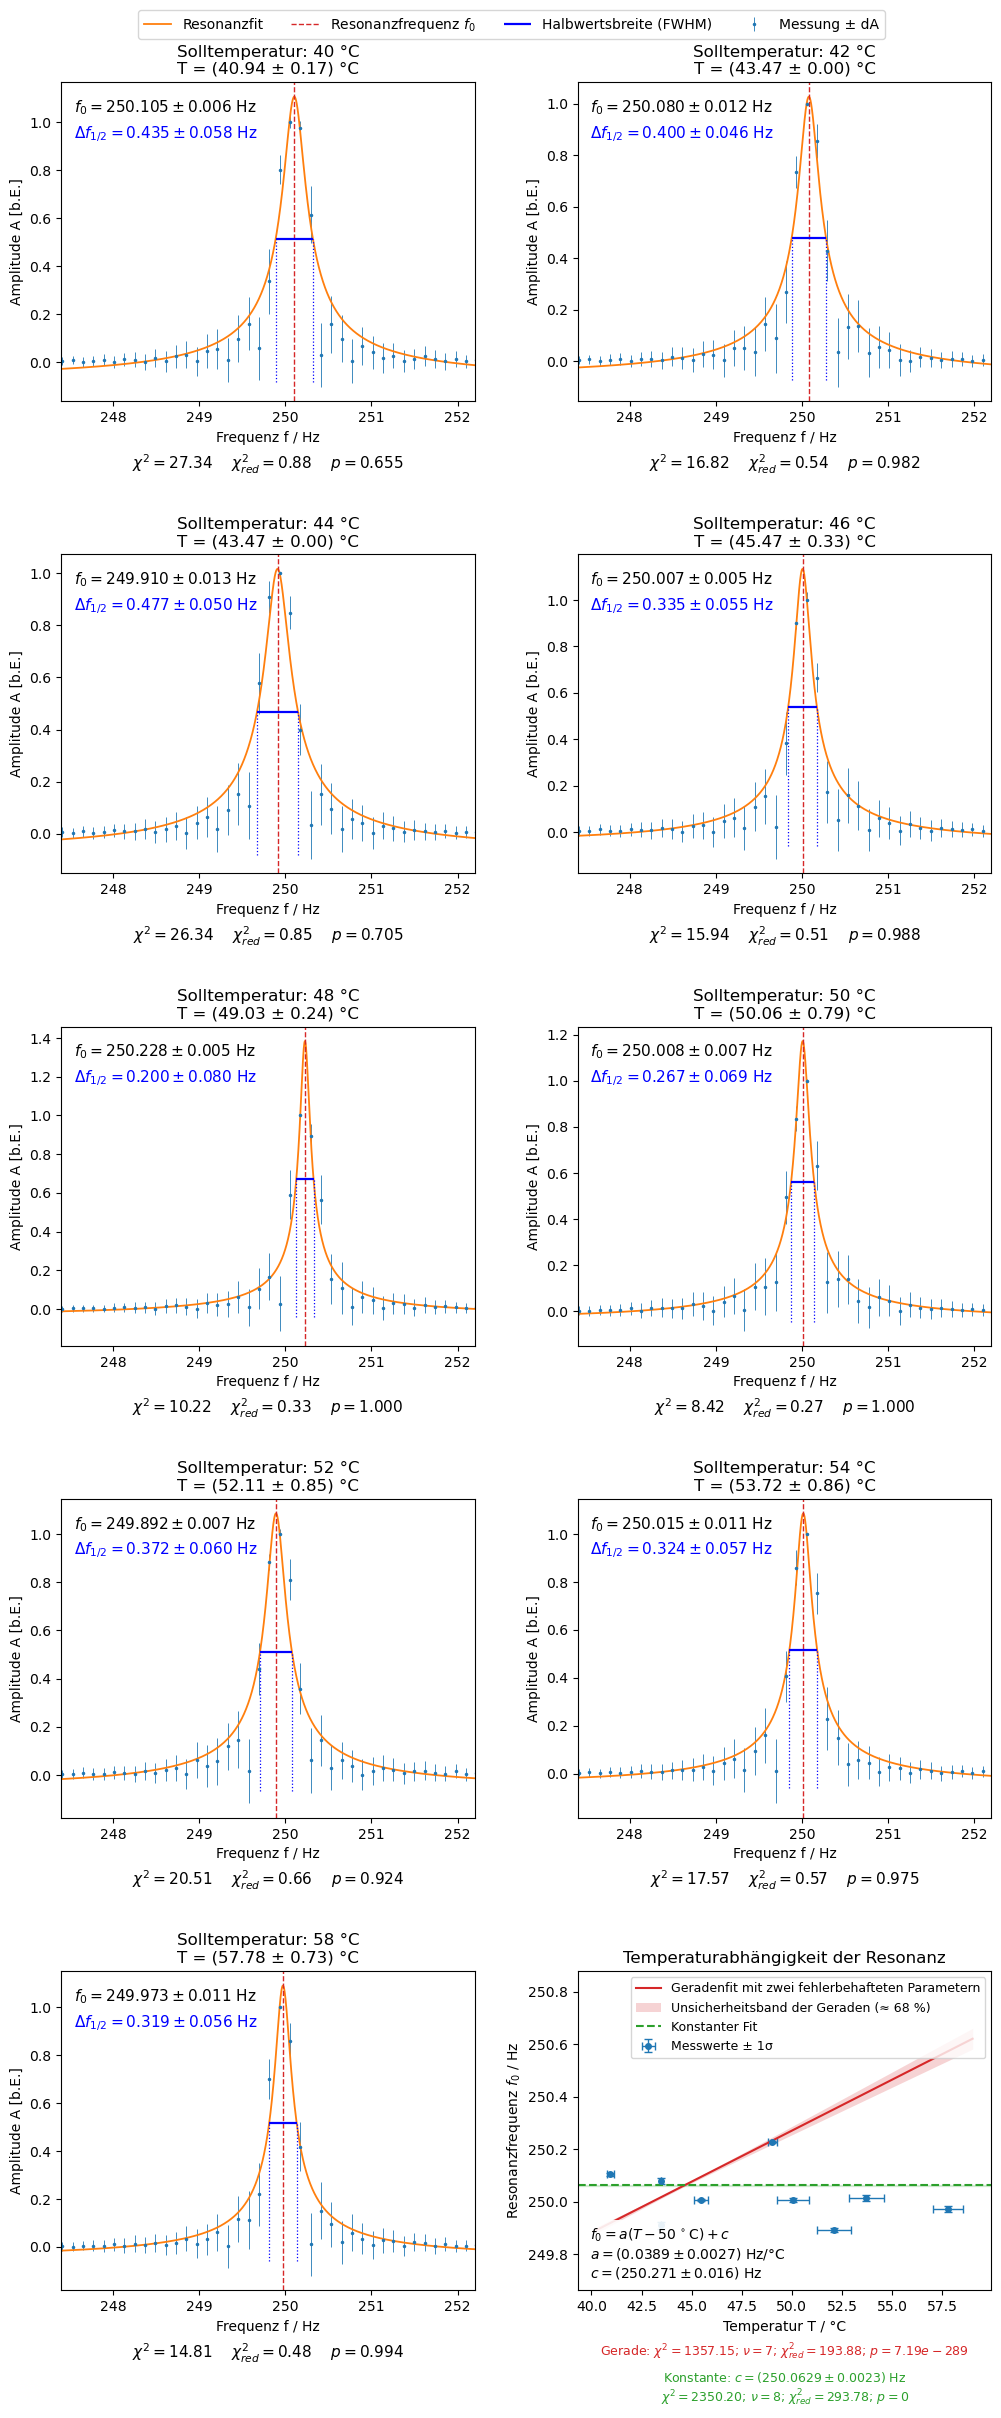

In [ ]:
def messseite(pc):
    gruppe = [
        m for m in messungen_fit
        if m["PC"] == pc and "p" in m
    ]
    if not gruppe:
        raise ValueError(f"Für {pc} wurden noch keine Resonanzfits berechnet.")

    bereiche = {
        "PC1": (247.4, 252.2),
        "PC2": (240, 260),
    }
    f_links, f_rechts = bereiche[pc]

    fig, achsen = plt.subplots(5, 2, figsize=(12, 24))
    fein = np.linspace(f_links, f_rechts, 2000)

    for ax, m in zip(achsen.flat, gruppe):
        d = m["daten"]

        # Dieselbe Normierung verwenden wie beim Resonanzfit.
        ax.errorbar(
            d.FQ, d.A/m["skala"], yerr=d.dA/m["skala"],
            fmt=".", ms=3, lw=0.6, color="C0",
            label="Messung ± dA"
        )
        ax.plot(
            fein, resonanz(fein, *m["p"]),
            color="C1", lw=1.3, label="Resonanzfit"
        )
        ax.axvline(
            m["f0"], color="C3", linestyle="--", lw=1,
            label="Resonanzfrequenz $f_0$"
        )

        # Halbwertsbreite: halbe Peakhöhe über dem Untergrund b.
        H, f0, g, b = m["p"]
        fmax2 = f0**2 - g**2/2
        wurzel = np.sqrt(3*(g**2*f0**2 - g**4/4))

        f_lo = np.sqrt(fmax2 - wurzel)
        f_hi = np.sqrt(fmax2 + wurzel)
        halb = b + (resonanz(np.sqrt(fmax2), *m["p"]) - b)/2

        ax.hlines(
            halb, f_lo, f_hi,
            color="blue", lw=1.6,
            label="Halbwertsbreite (FWHM)"
        )
        ax.vlines(
            [f_lo, f_hi], b, halb,
            color="blue", linestyle=":", lw=0.9
        )

        ax.text(
            0.03, 0.95,
            rf'$f_0 = {m["f0"]:.3f}\pm {m["df0"]:.3f}$ Hz',
            transform=ax.transAxes,
            fontsize=11, ha="left", va="top"
        )
        ax.text(
            0.03, 0.87,
            rf'$\Delta f_{{1/2}} = {m["breite"]:.3f}'
            rf'\pm {m["dbreite"]:.3f}$ Hz',
            transform=ax.transAxes,
            fontsize=11, color="blue", ha="left", va="top"
        )

        ax.set(
            xlim=(f_links, f_rechts),
            xlabel="Frequenz f / Hz",
            ylabel="Amplitude A [b.E.]",
            title=(
                f'Solltemperatur: {m["T_soll"]:g} °C\n'
                f'T = ({m["T"]:.2f} ± {m["sT"]:.2f}) °C'
)
        )

        chi2 = m["chi2"]
        ndf = m["ndf"]
        ax.text(
            0.5, -0.16,
            rf'$\chi^2 = {chi2:.2f}$    '
            rf'$\chi^2_{{red}} = {chi2/ndf:.2f}$    '
            rf'$p = {stats.chi2.sf(chi2, ndf):.3f}$',
            transform=ax.transAxes,
            fontsize=11, ha="center", va="top"
        )

    # Eventuell übrige Felder ausblenden; unten rechts folgt der Temperaturplot.
    for ax in list(achsen.flat)[len(gruppe):-1]:
        ax.axis("off")

    ax = achsen[-1, -1]
    r = temperaturfit(gruppe)

    ax.errorbar(
        r["T"], r["y"],
        xerr=r["sx"], yerr=r["sy"],
        fmt="o", ms=4, capsize=3, elinewidth=1,
        color="C0", label="Messwerte ± 1σ"
    )

    linie = np.linspace(
        np.min(r["T"] - r["sx"]) - 0.5,
        np.max(r["T"] + r["sx"]) + 0.5,
        300
    )
    ax.plot(
        linie, r["a"]*(linie - T_REF) + r["c"],
        color="C3", label="Geradenfit mit zwei fehlerbehafteten Parametern"
    )

    # Unsicherheit der angepassten Geraden einschließlich
    # der Korrelation zwischen Steigung a und Achsenabschnitt c.
    x_band = linie - T_REF
    y_band = r["a"] * x_band + r["c"]

    var_band = (
        x_band**2 * r["kov"][0, 0]
        + 2 * x_band * r["kov"][0, 1]
        + r["kov"][1, 1]
    )
    sigma_band = np.sqrt(np.maximum(var_band, 0))

    ax.fill_between(
        linie,
        y_band - sigma_band,
        y_band + sigma_band,
        color="C3",
        alpha=0.20,
        linewidth=0,
        label="Unsicherheitsband der Geraden (≈ 68 %)"
    )


        # Zusätzliches Modell ohne Steigung: f0(T) = konstant
    gewichte = 1 / r["sy"]**2

    c_konstant = np.sum(gewichte * r["y"]) / np.sum(gewichte)
    dc_konstant = np.sqrt(1 / np.sum(gewichte))

    chi2_konstant = np.sum(
        ((r["y"] - c_konstant) / r["sy"])**2
    )
    ndf_konstant = len(r["y"]) - 1  # Nur ein angepasster Parameter
    chi2_red_konstant = chi2_konstant / ndf_konstant
    p_konstant = stats.chi2.sf(chi2_konstant, ndf_konstant)

    ax.axhline(
        c_konstant,
        color="C2",
        linestyle="--",
        linewidth=1.5,
        label="Konstanter Fit"
    )

    # Formales 1σ-Unsicherheitsband des konstanten Wertes
    ax.axhspan(
        c_konstant - dc_konstant,
        c_konstant + dc_konstant,
        color="C2",
        alpha=0.15
    )

    print(
        f"{pc} – konstantes Modell:\n"
        f"  c = {c_konstant:.4f} ± {dc_konstant:.4f} Hz\n"
        f"  χ² = {chi2_konstant:.2f}\n"
        f"  Freiheitsgrade = {ndf_konstant}\n"
        f"  χ²_red = {chi2_red_konstant:.2f}\n"
        f"  p = {p_konstant:.3g}"
    )

    ax.set(
        xlabel="Temperatur T / °C",
        ylabel="Resonanzfrequenz $f_0$ / Hz",
        title="Temperaturabhängigkeit der Resonanz"
    )
    ax.ticklabel_format(axis="y", useOffset=False)
    ax.legend(loc="upper right", fontsize=9)
    ax.margins(y=0.28)

    ax.text(
        0.03, 0.03,
        rf'$f_0=a(T-{T_REF:g}\,^\circ\mathrm{{C}})+c$' + "\n"
        + rf'$a=({r["a"]:.4f}\pm {r["da"]:.4f})$ Hz/°C' + "\n"
        + rf'$c=({r["c"]:.3f}\pm {r["dc"]:.3f})$ Hz',
        transform=ax.transAxes,
        fontsize=10, va="bottom",
        bbox=dict(facecolor="white", alpha=0.9, edgecolor="none")
    )

    # Gütemaße des Geradenfits
    ax.text(
        0.5, -0.16,
        rf'Gerade: $\chi^2={r["chi2"]:.2f}$; '
        rf'$\nu={r["ndf"]}$; '
        rf'$\chi^2_{{red}}={r["chi2"]/r["ndf"]:.2f}$; '
        rf'$p={stats.chi2.sf(r["chi2"], r["ndf"]):.3g}$',
        transform=ax.transAxes,
        fontsize=9, ha="center", va="top",
        color="C3"
    )

    # Ergebnis und Gütemaße des konstanten Fits
    ax.text(
        0.5, -0.25,
        rf'Konstante: $c=({c_konstant:.4f}'
        rf'\pm {dc_konstant:.4f})$ Hz' + "\n"
        + rf'$\chi^2={chi2_konstant:.2f}$; '
        rf'$\nu={ndf_konstant}$; '
        rf'$\chi^2_{{red}}={chi2_red_konstant:.2f}$; '
        rf'$p={p_konstant:.3g}$',
        transform=ax.transAxes,
        fontsize=9, ha="center", va="top",
        color="C2"
    )

    handles, labels = achsen.flat[0].get_legend_handles_labels()
    fig.legend(
        handles, labels,
        loc="upper center", bbox_to_anchor=(0.5, 0.998),
        ncol=4, fontsize=10
    )
    fig.subplots_adjust(
        hspace=0.48, wspace=0.25,
        top=0.965, bottom=0.045
    )

    plt.show()
    return fig


plt.style.use("default")
fig_pc1 = messseite("PC1")

# Optional speichern:
# fig_pc1.savefig("PC1_Resonanzen.pdf", bbox_inches="tight")
# fig_pc1.savefig("PC1_Resonanzen.png", dpi=180, bbox_inches="tight")

## PC2

In [41]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy import stats

# ============================================================
# HIER ÄNDERN
# ============================================================
FIT_BEREICH_PC2 = (100.0, 420.0)
PLOT_BEREICH_PC2 = (100.0, 420.0)
# ============================================================

ordner_pc2 = Path(PROJEKT) / "important_data/PC2/WithTemp"
temperaturen_pc2 = [37, 40, 43, 46, 49, 52, 55, 58]

f_min, f_max = FIT_BEREICH_PC2
if not 0 < f_min < f_max:
    raise ValueError("Der Fitbereich muss positiv und aufsteigend sein.")

fits_pc2 = []

for temperatur in temperaturen_pc2:
    datei = f"final_TempFreq{temperatur:.1f}.csv"

    d = pd.read_csv(ordner_pc2 / datei)
    d = d[["FQ", "A", "dA", "T_set"]].apply(
        pd.to_numeric, errors="coerce"
    )
    d = d.loc[
        np.isfinite(d).all(axis=1) & (d["dA"] > 0)
    ].sort_values("FQ")

    # Nur dieser Ausschnitt wird gefittet.
    fitdaten = d.loc[d["FQ"].between(f_min, f_max)]

    if fitdaten["FQ"].nunique() < 5:
        raise ValueError(f"{datei}: Zu wenige Punkte im Fitbereich.")

    f = fitdaten["FQ"].to_numpy()
    A = fitdaten["A"].to_numpy()
    dA = fitdaten["dA"].to_numpy()

    skala = np.max(np.abs(A))
    if skala <= 0:
        raise ValueError(f"{datei}: Keine nutzbare Amplitude.")

    start_f0 = f[np.argmax(A)]
    start_b = np.min(A / skala)
    start_H = max(np.ptp(A / skala), 0.1)

    kandidaten = []

    # Breite obere Grenze; hält die abgeleitete FWHM reell.
    g_max = 0.5 * f_min

    for start_g in [0.03, 0.1, 0.3, 1.0, 3.0, 10.0]:
        if start_g >= g_max:
            continue

        try:
            p, kov = curve_fit(
                resonanz,
                f, A / skala,
                sigma=dA / skala,
                absolute_sigma=True,
                p0=[start_H, start_f0, start_g, start_b],
                bounds=(
                    [0, f_min, 1e-5, -np.inf],
                    [np.inf, f_max, g_max, np.inf]
                ),
                x_scale="jac",
                max_nfev=30000,
                ftol=1e-11,
                xtol=1e-11,
                gtol=1e-11
            )

            chi2 = np.sum(
                ((A/skala - resonanz(f, *p)) / (dA/skala))**2
            )
            kandidaten.append((chi2, p, kov))

        except (RuntimeError, ValueError):
            continue

    if not kandidaten:
        raise RuntimeError(f"{datei}: Kein Fit konvergiert.")

    chi2, p, kov = min(kandidaten, key=lambda eintrag: eintrag[0])

    
    m = {
        "Datei": datei,
        "daten": d,
        "T_soll": float(temperatur),
        "T": float(fitdaten["T_set"].mean()),
        "sT": float(fitdaten["T_set"].std(ddof=1)),
        "p": p,
        "kov": kov,
        "skala": skala,
        "chi2": float(chi2),
        "ndf": len(f) - 4,
    }


    namen = ["f0", "omega0", "fmax", "breite", "gamma", "Q", "b"]
    m.update(zip(namen, kenngroessen(p)))
    m.update(zip(
        ["d" + name for name in namen],
        fortpflanzung(p, kov)
    ))
    fits_pc2.append(m)

    # Kurze Hinweise auf schlecht eingeschränkte Fits.
    abstand = np.median(np.diff(np.unique(f)))

    if m["breite"] < 3 * abstand:
        print(f"Hinweis {datei}: Nur wenige Punkte über die Peakbreite.")
    if m["breite"] > f_max - f_min:
        print(f"Hinweis {datei}: Halbwertsbreite größer als Fitbereich.")
    if min(p[1] - f_min, f_max - p[1]) < 1e-3:
        print(f"Hinweis {datei}: f0 liegt an einer Fitgrenze.")
    if p[2] > 0.99 * g_max:
        print(f"Hinweis {datei}: Breitenparameter liegt an der Obergrenze.")

print(f"{len(fits_pc2)} PC2-Resonanzfits berechnet.")

8 PC2-Resonanzfits berechnet.


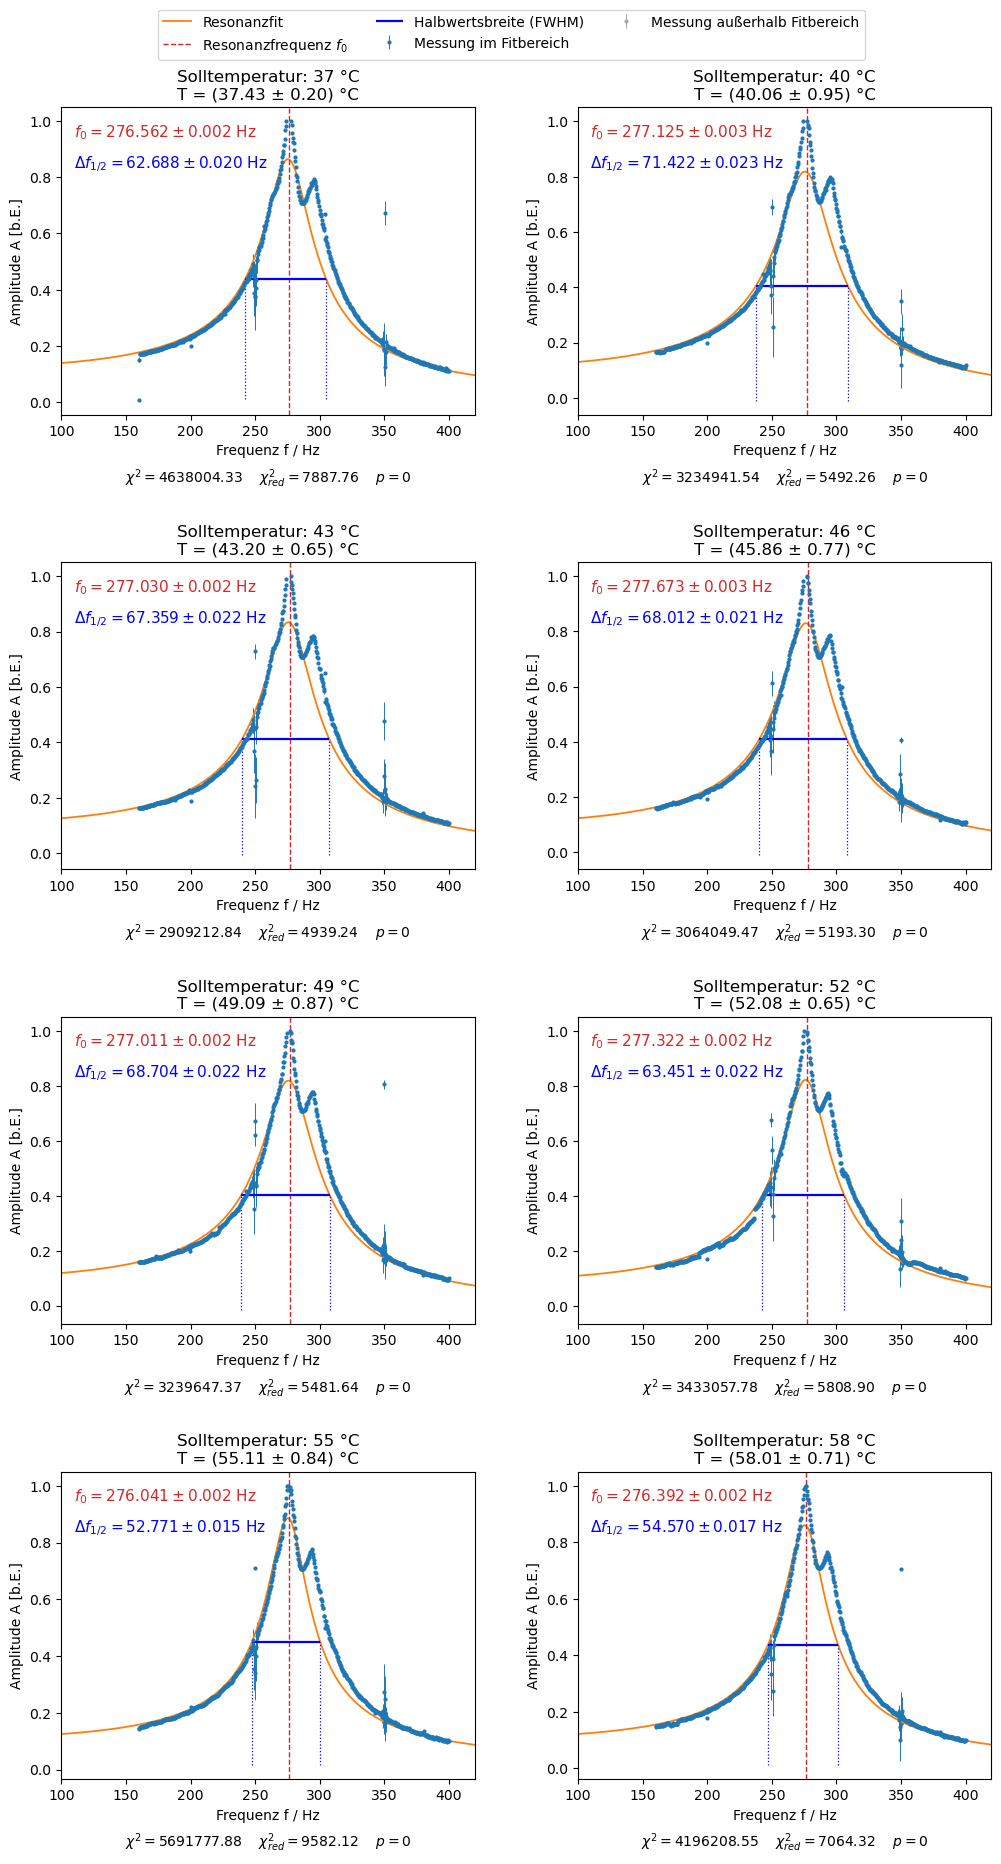

In [ ]:
plt.style.use("default")

fig_pc2, achsen = plt.subplots(4, 2, figsize=(12, 19))

plot_min, plot_max = PLOT_BEREICH_PC2
fein = np.linspace(plot_min, plot_max, 2500)

for ax, m in zip(achsen.flat, fits_pc2):
    d = m["daten"]
    sichtbar = d["FQ"].between(plot_min, plot_max)
    im_fit = d["FQ"].between(*FIT_BEREICH_PC2)

    # Verwendete Messpunkte in Blau
    ds = d.loc[sichtbar & im_fit]
    ax.errorbar(
        ds["FQ"], ds["A"] / m["skala"],
        yerr=ds["dA"] / m["skala"],
        fmt=".", ms=4, lw=0.7,
        color="C0", label="Messung im Fitbereich"
    )

    # Außerhalb des Fitbereichs liegende Messpunkte in Grau
    ds = d.loc[sichtbar & ~im_fit]
    ax.errorbar(
        ds["FQ"], ds["A"] / m["skala"],
        yerr=ds["dA"] / m["skala"],
        fmt=".", ms=4, lw=0.7,
        color="0.65", label="Messung außerhalb Fitbereich"
    )

    ax.plot(
        fein, resonanz(fein, *m["p"]),
        color="C1", lw=1.3, label="Resonanzfit"
    )
    ax.axvline(
        m["f0"], color="C3", ls="--", lw=1,
        label="Resonanzfrequenz $f_0$"
    )

    # FWHM der Amplitude relativ zum angepassten Untergrund
    H, f0, g, b = m["p"]
    fmax2 = f0**2 - g**2 / 2
    wurzel = np.sqrt(3 * (g**2 * f0**2 - g**4 / 4))

    f_lo = np.sqrt(fmax2 - wurzel)
    f_hi = np.sqrt(fmax2 + wurzel)
    halb = b + (resonanz(np.sqrt(fmax2), *m["p"]) - b) / 2

    ax.hlines(
        halb, f_lo, f_hi,
        color="blue", lw=1.6,
        label="Halbwertsbreite (FWHM)"
    )
    ax.vlines(
        [f_lo, f_hi], b, halb,
        color="blue", ls=":", lw=0.9
    )

    fehler_f0 = m["df0"]  # Formale Fitunsicherheit

    ax.text(
        0.03, 0.95,
        rf'$f_0={m["f0"]:.3f}\pm {fehler_f0:.3f}$ Hz',
        transform=ax.transAxes,
        fontsize=11, color="C3", va="top",
        bbox=dict(facecolor="white", alpha=0.8, edgecolor="none")
    )
    ax.text(
        0.03, 0.85,
        rf'$\Delta f_{{1/2}}={m["breite"]:.3f}'
        rf'\pm {m["dbreite"]:.3f}$ Hz',
        transform=ax.transAxes,
        fontsize=11, color="blue", va="top",
        bbox=dict(facecolor="white", alpha=0.8, edgecolor="none")
    )

    ax.set(
        xlim=(plot_min, plot_max),
        xlabel="Frequenz f / Hz",
        ylabel="Amplitude A [b.E.]",
        title=(
            f'Solltemperatur: {m["T_soll"]:g} °C\n'
            f'T = ({m["T"]:.2f} ± {m["sT"]:.2f}) °C'
        )
    )

    chi2 = m["chi2"]
    ndf = m["ndf"]
    ax.text(
        0.5, -0.17,
        rf'$\chi^2={chi2:.2f}$    '
        rf'$\chi^2_{{red}}={chi2/ndf:.2f}$    '
        rf'$p={stats.chi2.sf(chi2, ndf):.3g}$',
        transform=ax.transAxes,
        fontsize=10, ha="center", va="top"
    )

handles, labels = achsen.flat[0].get_legend_handles_labels()
fig_pc2.legend(
    handles, labels,
    loc="upper center", bbox_to_anchor=(0.5, 0.995),
    ncol=3, fontsize=10
)

fig_pc2.subplots_adjust(
    hspace=0.48, wspace=0.25,
    top=0.94, bottom=0.06
)

plt.show()

# Optional speichern:
# fig_pc2.savefig("PC2_Resonanzen.pdf", bbox_inches="tight")
# fig_pc2.savefig("PC2_Resonanzen.png", dpi=180, bbox_inches="tight")

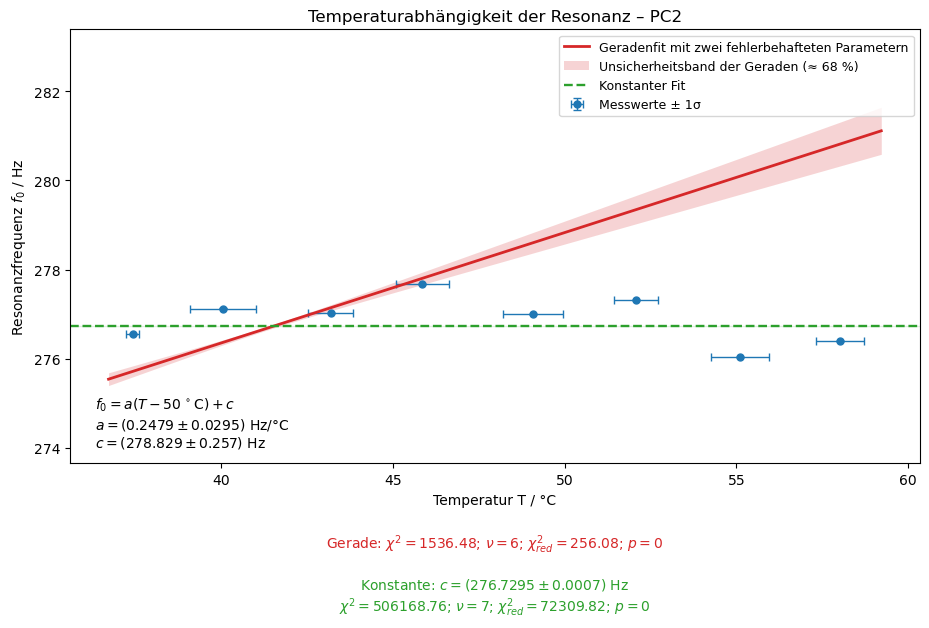

In [43]:

# ============================================================
# PC2: Temperaturabhängigkeit der Resonanzfrequenz
# Eigenständiger Plot, analog zu PC1
# ============================================================

from scipy import stats

# Dieselbe Fitfunktion wie bei PC1 verwenden.
# Temperaturfehler: 1.5 °C (aus TEMPERATURFEHLER)
r = temperaturfit(fits_pc2)

fig_temperatur_pc2, ax = plt.subplots(figsize=(10, 7))
fig_temperatur_pc2.subplots_adjust(
    left=0.12, right=0.97, top=0.92, bottom=0.30
)

# Messwerte mit Unsicherheiten in beiden Achsen
ax.errorbar(
    r["T"], r["y"],
    xerr=r["sx"], yerr=r["sy"],
    fmt="o", ms=5, capsize=3, elinewidth=1,
    color="C0", label="Messwerte ± 1σ"
)

# Temperaturbereich für die Fitgeraden
linie = np.linspace(
    np.min(r["T"] - r["sx"]) - 0.5,
    np.max(r["T"] + r["sx"]) + 0.5,
    300
)

# Linearer Fit: f0 = a * (T - T_REF) + c
x_band = linie - T_REF
y_band = r["a"] * x_band + r["c"]

ax.plot(
    linie, y_band,
    color="C3", lw=2,
    label="Geradenfit mit zwei fehlerbehafteten Parametern"
)

# 1σ-Unsicherheitsband einschließlich Parameterkorrelation
var_band = (
    x_band**2 * r["kov"][0, 0]
    + 2 * x_band * r["kov"][0, 1]
    + r["kov"][1, 1]
)
sigma_band = np.sqrt(np.maximum(var_band, 0))

ax.fill_between(
    linie,
    y_band - sigma_band,
    y_band + sigma_band,
    color="C3", alpha=0.20, linewidth=0,
    label="Unsicherheitsband der Geraden (≈ 68 %)"
)

# ------------------------------------------------------------
# Vergleichsmodell: konstante Resonanzfrequenz
# ------------------------------------------------------------
gewichte = 1 / r["sy"]**2

c_konstant = np.sum(gewichte * r["y"]) / np.sum(gewichte)
dc_konstant = np.sqrt(1 / np.sum(gewichte))

chi2_konstant = np.sum(
    ((r["y"] - c_konstant) / r["sy"])**2
)
ndf_konstant = len(r["y"]) - 1
chi2_red_konstant = chi2_konstant / ndf_konstant
p_konstant = stats.chi2.sf(chi2_konstant, ndf_konstant)

ax.axhline(
    c_konstant,
    color="C2", linestyle="--", linewidth=1.7,
    label="Konstanter Fit"
)

ax.axhspan(
    c_konstant - dc_konstant,
    c_konstant + dc_konstant,
    color="C2", alpha=0.15
)

# ------------------------------------------------------------
# Beschriftungen und Ergebnisse
# ------------------------------------------------------------
ax.set(
    xlabel="Temperatur T / °C",
    ylabel="Resonanzfrequenz $f_0$ / Hz",
    title="Temperaturabhängigkeit der Resonanz – PC2"
)

ax.ticklabel_format(axis="y", useOffset=False)
ax.legend(loc="upper right", fontsize=9)
ax.margins(y=0.28)

# Parameter des linearen Fits im Diagramm
ax.text(
    0.03, 0.03,
    rf'$f_0=a(T-{T_REF:g}\,^\circ\mathrm{{C}})+c$' + "\n"
    + rf'$a=({r["a"]:.4f}\pm {r["da"]:.4f})$ Hz/°C' + "\n"
    + rf'$c=({r["c"]:.3f}\pm {r["dc"]:.3f})$ Hz',
    transform=ax.transAxes,
    fontsize=10, va="bottom",
    bbox=dict(facecolor="white", alpha=0.9, edgecolor="none")
)

# Gütemaße des linearen Fits
ax.text(
    0.5, -0.16,
    rf'Gerade: $\chi^2={r["chi2"]:.2f}$; '
    rf'$\nu={r["ndf"]}$; '
    rf'$\chi^2_{{red}}={r["chi2"]/r["ndf"]:.2f}$; '
    rf'$p={stats.chi2.sf(r["chi2"], r["ndf"]):.3g}$',
    transform=ax.transAxes,
    fontsize=10, ha="center", va="top",
    color="C3"
)

# Gütemaße des konstanten Fits
ax.text(
    0.5, -0.26,
    rf'Konstante: $c=({c_konstant:.4f}'
    rf'\pm {dc_konstant:.4f})$ Hz' + "\n"
    + rf'$\chi^2={chi2_konstant:.2f}$; '
    rf'$\nu={ndf_konstant}$; '
    rf'$\chi^2_{{red}}={chi2_red_konstant:.2f}$; '
    rf'$p={p_konstant:.3g}$',
    transform=ax.transAxes,
    fontsize=10, ha="center", va="top",
    color="C2"
)

plt.show()

# Optional speichern:
# fig_temperatur_pc2.savefig(
#     "PC2_Temperaturabhaengigkeit.pdf", bbox_inches="tight"
# )


PC1, Solltemperatur 52 °C:
  Anzahl Fitmesspunkte: 35
  Temperaturmittelwert: 52.1102 °C
  Standardabweichung (N-1): 0.8524 °C

PC1, Solltemperatur 54 °C:
  Anzahl Fitmesspunkte: 35
  Temperaturmittelwert: 53.7176 °C
  Standardabweichung (N-1): 0.8584 °C



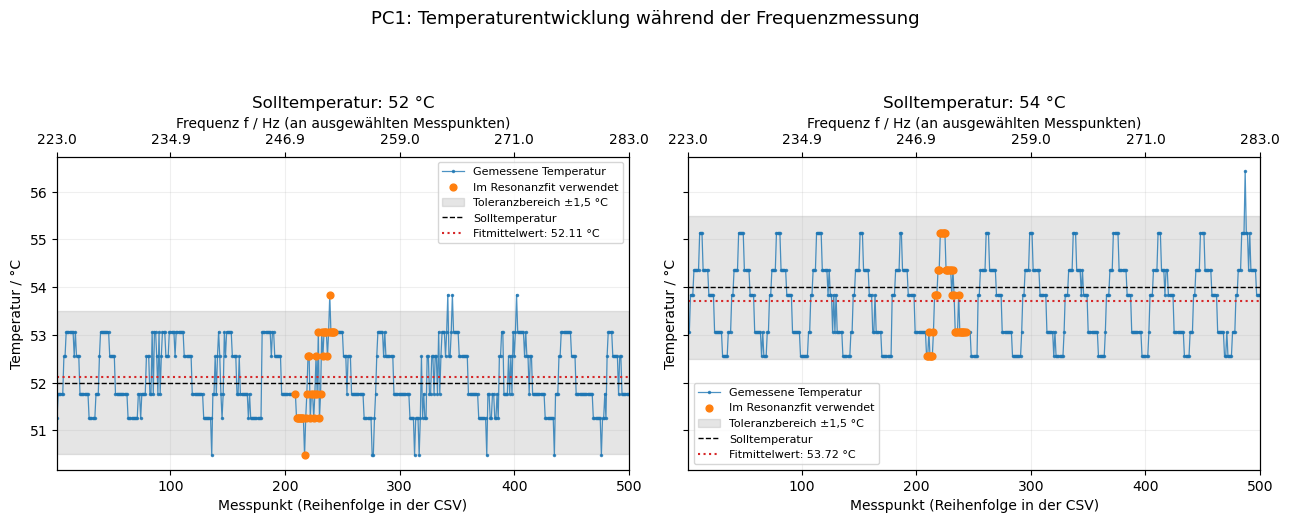

In [44]:

# ============================================================
# PC1: Temperaturentwicklung während der Messung
# Solltemperaturen 52 °C und 54 °C
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

fig, achsen = plt.subplots(
    1, 2, figsize=(13, 4.8), sharey=True
)

for ax, T_soll in zip(achsen, [52, 54]):

    datei = f"TempFreq{T_soll}.csv"
    pfad = (
        Path(PROJEKT)
        / "important_data/PC1/PC1_final_WithTemp"
        / datei
    )

    # Originalreihenfolge der CSV beibehalten!
    d = pd.read_csv(pfad)
    d = d[["FQ", "A", "dA", "T_set"]].apply(
        pd.to_numeric, errors="coerce"
    )

    # 1, 2, 3, ... entsprechend den Datenzeilen
    zeilen = np.arange(1, len(d) + 1)

    # Alle Messzeilen mit gültiger Temperatur und Frequenz
    gueltig = (
        np.isfinite(d["T_set"])
        & np.isfinite(d["FQ"])
    )

    # Exakt dieselben Auswahlbedingungen wie beim PC1-Fit
    fitmaske = (
        np.isfinite(d).all(axis=1)
        & (d["dA"] > 0)
        & d["FQ"].between(F_MIN, F_MAX)
    )

    # Gesamter Temperaturverlauf in Messreihenfolge
    ax.plot(
        zeilen[gueltig],
        d.loc[gueltig, "T_set"],
        ".-",
        color="C0",
        markersize=3,
        linewidth=0.9,
        alpha=0.8,
        label="Gemessene Temperatur"
    )

    # Punkte hervorheben, die in den Resonanzfit eingehen
    ax.scatter(
        zeilen[fitmaske],
        d.loc[fitmaske, "T_set"],
        color="C1",
        s=24,
        zorder=4,
        label="Im Resonanzfit verwendet"
    )

    # Solltemperatur und Toleranzbereich ±1.5 °C
    ax.axhspan(
        T_soll - 1.5,
        T_soll + 1.5,
        color="gray",
        alpha=0.20,
        label="Toleranzbereich ±1,5 °C"
    )

    ax.axhline(
        T_soll,
        color="black",
        linestyle="--",
        linewidth=1,
        label="Solltemperatur"
    )

    # Temperaturstatistik nur der Fitmesspunkte
    T_fit = d.loc[fitmaske, "T_set"]

    if len(T_fit) < 2:
        raise ValueError(
            f"{datei}: Zu wenige Temperaturwerte im Fitbereich."
        )

    T_mittel = T_fit.mean()
    T_std = T_fit.std(ddof=1)

    # Mittelwert im Diagramm markieren
    ax.axhline(
        T_mittel,
        color="C3",
        linestyle=":",
        linewidth=1.5,
        label=f"Fitmittelwert: {T_mittel:.2f} °C"
    )

    ax.set(
        title=f"Solltemperatur: {T_soll:g} °C",
        xlabel="Messpunkt (Reihenfolge in der CSV)",
        ylabel="Temperatur / °C"
    )

    ax.set_xlim(1, len(d))
    ax.grid(True, alpha=0.2)
    ax.legend(fontsize=8, loc="best")

    # Obere Achse: Frequenzwerte an ausgewählten Zeilen
    oben = ax.twiny()
    oben.set_xlim(ax.get_xlim())

    positionen = np.unique(
        np.linspace(0, len(d) - 1, 6, dtype=int)
    )

    oben.set_xticks(positionen + 1)
    oben.set_xticklabels([
        f"{d['FQ'].iloc[i]:.1f}"
        if np.isfinite(d["FQ"].iloc[i])
        else "–"
        for i in positionen
    ])

    oben.set_xlabel(
        "Frequenz f / Hz (an ausgewählten Messpunkten)"
    )

    print(
        f"PC1, Solltemperatur {T_soll} °C:\n"
        f"  Anzahl Fitmesspunkte: {len(T_fit)}\n"
        f"  Temperaturmittelwert: {T_mittel:.4f} °C\n"
        f"  Standardabweichung (N-1): {T_std:.4f} °C\n"
    )

fig.suptitle(
    "PC1: Temperaturentwicklung während der Frequenzmessung",
    fontsize=13,
    y=1.08
)

fig.tight_layout()
plt.show()

# Optional speichern:
# fig.savefig("PC1_Temperaturverlauf_52_54.pdf",
#             bbox_inches="tight")


### Bereinigter Fit für PC2

final_TempFreq37.0.csv: X gesättigt: 28, Y gesättigt: 46, insgesamt ausgeschlossen: 74, Fitpunkte: 518
  T = (37.420 ± 0.211) °C, f0 = (281.635 ± 0.005) Hz, χ²_red = 46.07
final_TempFreq40.0.csv: X gesättigt: 28, Y gesättigt: 47, insgesamt ausgeschlossen: 75, Fitpunkte: 518
  T = (40.220 ± 0.901) °C, f0 = (281.550 ± 0.005) Hz, χ²_red = 38.36
final_TempFreq43.0.csv: X gesättigt: 26, Y gesättigt: 46, insgesamt ausgeschlossen: 72, Fitpunkte: 521
  T = (43.191 ± 0.664) °C, f0 = (281.488 ± 0.005) Hz, χ²_red = 18.55
final_TempFreq46.0.csv: X gesättigt: 25, Y gesättigt: 46, insgesamt ausgeschlossen: 71, Fitpunkte: 523
  T = (45.860 ± 0.777) °C, f0 = (281.608 ± 0.005) Hz, χ²_red = 22.60
final_TempFreq49.0.csv: X gesättigt: 24, Y gesättigt: 44, insgesamt ausgeschlossen: 68, Fitpunkte: 527
  T = (49.088 ± 0.865) °C, f0 = (281.461 ± 0.005) Hz, χ²_red = 55.13
final_TempFreq52.0.csv: X gesättigt: 24, Y gesättigt: 42, insgesamt ausgeschlossen: 66, Fitpunkte: 529
  T = (52.091 ± 0.651) °C, f0 = (282.

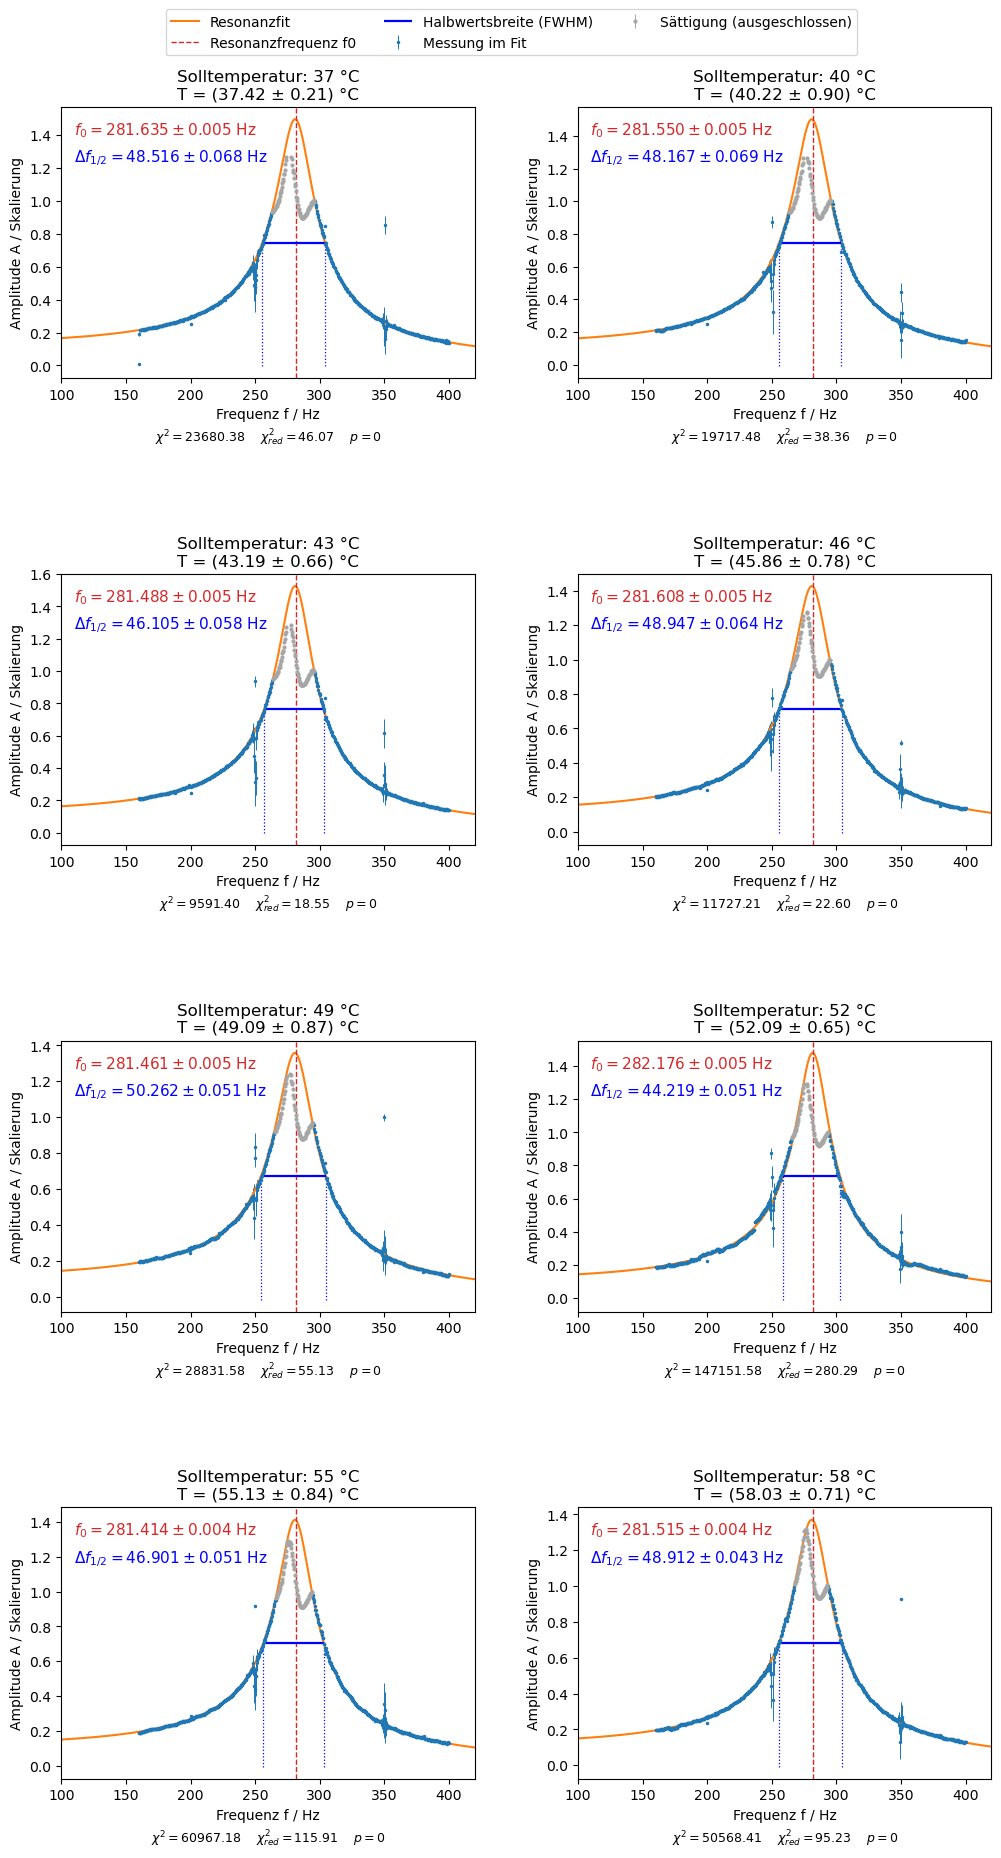

In [56]:

# ============================================================
# PC2: Resonanzfits ohne gesättigte X- oder Y-Messwerte
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.optimize import curve_fit
from scipy import stats
import warnings

# Einstellungen zur Plateau-Erkennung
MIN_PLATEAU_LAENGE = 5
PLATEAU_TOLERANZ = 1e-4  # Relativ zur Spannweite des Signals

# Spaltennamen in den Original-CSV-Dateien
SPALTE_X = "QX"
SPALTE_Y = "QY"

# Dieselben Frequenzbereiche wie bei den bisherigen PC2-Fits
FIT_BEREICH_NEU = FIT_BEREICH_PC2
PLOT_BEREICH_NEU = PLOT_BEREICH_PC2

ordner = Path(PROJEKT) / "important_data/PC2/WithTemp"
temperaturen = [37, 40, 43, 46, 49, 52, 55, 58]


def erkenne_saettigung(werte):
    """
    Erkennt zusammenhängende Plateaus am Maximum eines Signals.

    Ein Plateau muss mindestens MIN_PLATEAU_LAENGE
    aufeinanderfolgende Werte innerhalb der Toleranz haben.
    """
    werte = np.asarray(werte, dtype=float)

    maske = np.zeros(len(werte), dtype=bool)

    maximum = np.max(werte)
    toleranz = max(
        1e-10,
        PLATEAU_TOLERANZ * np.ptp(werte)
    )

    nahe_maximum = np.abs(werte - maximum) <= toleranz
    kandidaten = np.flatnonzero(nahe_maximum)

    if len(kandidaten) == 0:
        return maske

    # Zusammenhängende Bereiche bilden
    bloecke = np.split(
        kandidaten,
        np.flatnonzero(np.diff(kandidaten) != 1) + 1
    )

    for block in bloecke:
        if len(block) >= MIN_PLATEAU_LAENGE:
            maske[block] = True

    return maske


fits_pc2_ohne_saettigung = []

f_min, f_max = FIT_BEREICH_NEU
g_max = 0.5 * f_min

for temperatur in temperaturen:

    datei = f"final_TempFreq{temperatur:.1f}.csv"

    # Originaldatei laden, einschließlich X und Y
    d = pd.read_csv(ordner / datei)
    d.columns = d.columns.str.strip()

    benoetigt = [
        "FQ", "A", "dA", "T_set", SPALTE_X, SPALTE_Y
    ]

    fehlend = [s for s in benoetigt if s not in d.columns]
    if fehlend:
        raise ValueError(
            f"{datei}: Spalten {fehlend} fehlen. "
            f"Vorhanden: {list(d.columns)}"
        )

    d = d[benoetigt].copy()
    d = d.rename(columns={
        SPALTE_X: "X",
        SPALTE_Y: "Y"
    })

    d = d.apply(pd.to_numeric, errors="coerce")

    gueltig = (
        np.isfinite(d).all(axis=1)
        & (d["dA"] > 0)
    )

    d = (
        d.loc[gueltig]
        .sort_values("FQ")
        .reset_index(drop=True)
    )

    im_bereich = d["FQ"].between(f_min, f_max)
    indizes = np.flatnonzero(im_bereich.to_numpy())

    # Sättigung für X und Y getrennt ermitteln
    saett_x = np.zeros(len(d), dtype=bool)
    saett_y = np.zeros(len(d), dtype=bool)

    saett_x[indizes] = erkenne_saettigung(
        d.loc[im_bereich, "X"].to_numpy()
    )
    saett_y[indizes] = erkenne_saettigung(
        d.loc[im_bereich, "Y"].to_numpy()
    )

    # Schon eine gesättigte Komponente genügt
    saettigung = saett_x | saett_y

    d["saett_x"] = saett_x
    d["saett_y"] = saett_y
    d["saettigung"] = saettigung

    # Ausschließlich ungesättigte Messwerte fitten
    fitmaske = im_bereich & ~d["saettigung"]
    d["im_fit"] = fitmaske

    fitdaten = d.loc[fitmaske]

    if len(fitdaten) < 8 or fitdaten["FQ"].nunique() < 5:
        raise ValueError(
            f"{datei}: Zu wenige ungesättigte Fitpunkte."
        )

    f = fitdaten["FQ"].to_numpy()
    A = fitdaten["A"].to_numpy()
    dA = fitdaten["dA"].to_numpy()

    # Temperaturstatistik nur über echte Fitpunkte
    T = float(fitdaten["T_set"].mean())
    sT = float(fitdaten["T_set"].std(ddof=1))

    # Amplitude wie zuvor skalieren
    skala = np.max(np.abs(A))

    start_H = max(np.ptp(A / skala), 0.1)
    start_b = np.min(A / skala)

    # Alten Fit als sinnvollen Startwert nutzen
    alter_fit = next(
        (m for m in fits_pc2 if m["Datei"] == datei),
        None
    )

    if alter_fit is not None:
        start_f0 = float(alter_fit["f0"])
        start_g_alt = float(alter_fit["p"][2])
    else:
        start_f0 = float(f[np.argmax(A)])
        start_g_alt = 10.0

    start_f0 = np.clip(start_f0, f_min, f_max)

    kandidaten = []

    for start_g in [
        0.1, 1.0, 3.0, 10.0, 20.0, 40.0, start_g_alt
    ]:

        if not 0 < start_g < g_max:
            continue

        try:
            p, kov = curve_fit(
                resonanz,
                f,
                A / skala,
                sigma=dA / skala,
                absolute_sigma=True,
                p0=[start_H, start_f0, start_g, start_b],
                bounds=(
                    [0, f_min, 1e-5, -np.inf],
                    [np.inf, f_max, g_max, np.inf]
                ),
                x_scale="jac",
                max_nfev=30000,
                ftol=1e-11,
                xtol=1e-11,
                gtol=1e-11
            )

            chi2 = float(np.sum(
                ((A/skala - resonanz(f, *p))
                 / (dA/skala))**2
            ))

            kandidaten.append((chi2, p, kov))

        except (RuntimeError, ValueError):
            continue

    if not kandidaten:
        raise RuntimeError(
            f"{datei}: Kein Resonanzfit konvergiert."
        )

    chi2, p, kov = min(
        kandidaten,
        key=lambda eintrag: eintrag[0]
    )

    # Ergebnisse speichern
    m = {
        "Datei": datei,
        "daten": d,
        "T_soll": float(temperatur),
        "T": T,
        "sT": sT,
        "p": p,
        "kov": kov,
        "skala": skala,
        "chi2": chi2,
        "ndf": len(f) - 4,
        "n_fit": len(f),
        "n_saettigung": int(saettigung.sum()),
    }

    namen = [
        "f0", "omega0", "fmax",
        "breite", "gamma", "Q", "b"
    ]

    m.update(zip(namen, kenngroessen(p)))
    m.update(zip(
        ["d" + name for name in namen],
        fortpflanzung(p, kov)
    ))

    fits_pc2_ohne_saettigung.append(m)

    print(
        f"{datei}: "
        f"X gesättigt: {saett_x.sum()}, "
        f"Y gesättigt: {saett_y.sum()}, "
        f"insgesamt ausgeschlossen: {saettigung.sum()}, "
        f"Fitpunkte: {len(f)}"
    )

    print(
        f"  T = ({T:.3f} ± {sT:.3f}) °C, "
        f"f0 = ({m['f0']:.3f} ± {m['df0']:.3f}) Hz, "
        f"χ²_red = {chi2/m['ndf']:.2f}"
    )

    if not np.any(saettigung):
        warnings.warn(
            f"{datei}: Kein Sättigungsplateau erkannt."
        )


# ============================================================
# Neue PC2-Messseite mit 8 Diagrammen
# ============================================================

plt.style.use("default")

fig_pc2_bereinigt, achsen = plt.subplots(
    4, 2, figsize=(12, 19)
)

plot_min, plot_max = PLOT_BEREICH_NEU
fein = np.linspace(plot_min, plot_max, 2500)

for ax, m in zip(achsen.flat, fits_pc2_ohne_saettigung):

    d = m["daten"]
    sichtbar = d["FQ"].between(plot_min, plot_max)

    # Blau: Punkte, die tatsächlich gefittet wurden
    ds = d.loc[sichtbar & d["im_fit"]]

    ax.errorbar(
        ds["FQ"], ds["A"] / m["skala"],
        yerr=ds["dA"] / m["skala"],
        fmt=".", ms=3, lw=0.7,
        color="C0",
        label="Messung im Fit"
    )

    # Grau: gesättigte, ausgeschlossene Punkte
    ds = d.loc[sichtbar & d["saettigung"]]

    ax.errorbar(
        ds["FQ"], ds["A"] / m["skala"],
        yerr=ds["dA"] / m["skala"],
        fmt=".", ms=4, lw=0.7,
        color="0.65",
        label="Sättigung (ausgeschlossen)"
    )

    # Sonstige Punkte außerhalb des Fitbereichs
    ds = d.loc[
        sichtbar
        & ~d["im_fit"]
        & ~d["saettigung"]
    ]

    if len(ds):
        ax.errorbar(
            ds["FQ"], ds["A"] / m["skala"],
            yerr=ds["dA"] / m["skala"],
            fmt=".", ms=3, lw=0.7,
            color="0.85",
            label="Außerhalb des Fitbereichs"
        )

    # Lorentzfit
    ax.plot(
        fein, resonanz(fein, *m["p"]),
        color="C1", lw=1.5,
        label="Resonanzfit"
    )

    ax.axvline(
        m["f0"],
        color="C3", linestyle="--", lw=1,
        label="Resonanzfrequenz f0"
    )

    # FWHM wie im bisherigen Notebook
    H, f0, g, b = m["p"]

    fmax2 = f0**2 - g**2/2
    wurzel = np.sqrt(
        3 * (g**2*f0**2 - g**4/4)
    )

    f_lo = np.sqrt(fmax2 - wurzel)
    f_hi = np.sqrt(fmax2 + wurzel)

    halb = b + (
        resonanz(np.sqrt(fmax2), *m["p"]) - b
    ) / 2

    ax.hlines(
        halb, f_lo, f_hi,
        color="blue", lw=1.6,
        label="Halbwertsbreite (FWHM)"
    )

    ax.vlines(
        [f_lo, f_hi], b, halb,
        color="blue", linestyle=":", lw=0.9
    )

    # Fitparameter
    ax.text(
        0.03, 0.95,
        rf'$f_0={m["f0"]:.3f}\pm {m["df0"]:.3f}$ Hz',
        transform=ax.transAxes,
        fontsize=11, color="C3", va="top",
        bbox=dict(facecolor="white", alpha=0.85,
                  edgecolor="none")
    )

    ax.text(
        0.03, 0.85,
        rf'$\Delta f_{{1/2}}={m["breite"]:.3f}'
        rf'\pm {m["dbreite"]:.3f}$ Hz',
        transform=ax.transAxes,
        fontsize=11, color="blue", va="top",
        bbox=dict(facecolor="white", alpha=0.85,
                  edgecolor="none")
    )

    ax.set(
        xlim=(plot_min, plot_max),
        xlabel="Frequenz f / Hz",
        ylabel="Amplitude A / Skalierung",
        title=(
            f'Solltemperatur: {m["T_soll"]:g} °C\n'
            f'T = ({m["T"]:.2f} ± {m["sT"]:.2f}) °C'
        )
    )

    chi2 = m["chi2"]
    ndf = m["ndf"]

    ax.text(
        0.5, -0.18,
        rf'$\chi^2={chi2:.2f}$    '
        rf'$\chi^2_{{red}}={chi2/ndf:.2f}$    '
        rf'$p={stats.chi2.sf(chi2, ndf):.3g}$',
        transform=ax.transAxes,
        ha="center", va="top", fontsize=9
    )

handles, labels = achsen.flat[0].get_legend_handles_labels()

fig_pc2_bereinigt.legend(
    handles, labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.995),
    ncol=3, fontsize=10
)

fig_pc2_bereinigt.subplots_adjust(
    hspace=0.72,
    wspace=0.25,
    top=0.94,
    bottom=0.06
)

plt.show()

# Optional:
# fig_pc2_bereinigt.savefig(
#     "PC2_Resonanzen_ohne_Saettigung.pdf",
#     bbox_inches="tight"
# )


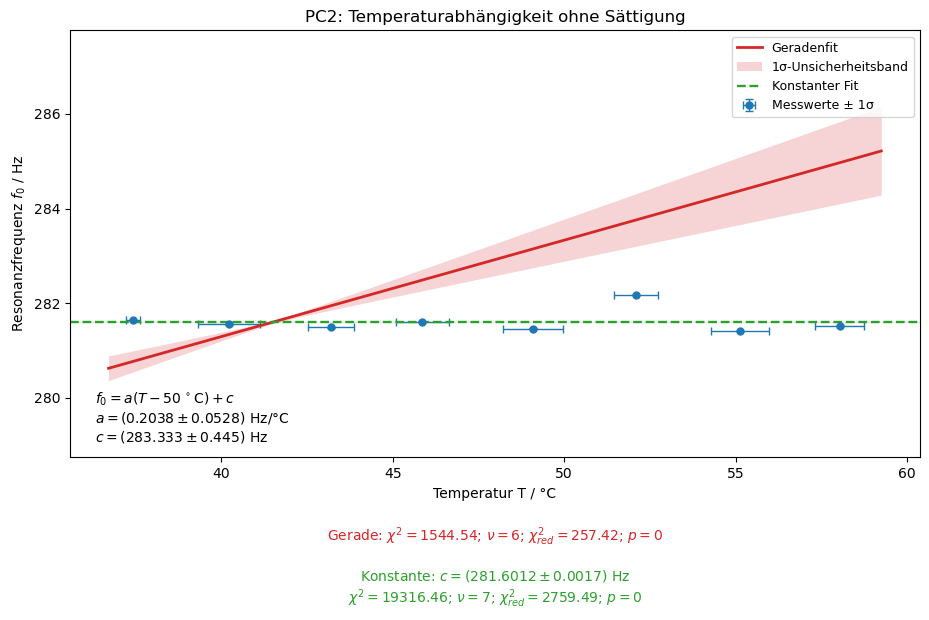


PC2 ohne Sättigung – linearer Fit:
a = 0.203788 ± 0.052765 Hz/°C
c = 283.332580 ± 0.444806 Hz
χ²_red = 257.424
p = 0

Konstanter Fit:
c = 281.601187 ± 0.001669 Hz
χ²_red = 2759.495
p = 0


In [57]:

# ============================================================
# PC2: Temperaturabhängigkeit ohne gesättigte Messwerte
# Linearer Fit + konstanter Vergleichsfit
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

r = temperaturfit(fits_pc2_ohne_saettigung)

fig_temperatur_pc2_bereinigt, ax = plt.subplots(
    figsize=(10, 7)
)

fig_temperatur_pc2_bereinigt.subplots_adjust(
    left=0.12, right=0.97,
    top=0.91, bottom=0.30
)

# Messwerte mit x- und y-Unsicherheiten
ax.errorbar(
    r["T"], r["y"],
    xerr=r["sx"], yerr=r["sy"],
    fmt="o", ms=5, capsize=3,
    elinewidth=1, color="C0",
    label="Messwerte ± 1σ"
)

linie = np.linspace(
    np.min(r["T"] - r["sx"]) - 0.5,
    np.max(r["T"] + r["sx"]) + 0.5,
    300
)

# Linearer Fit
x = linie - T_REF
y = r["a"] * x + r["c"]

ax.plot(
    linie, y,
    color="C3", lw=2,
    label="Geradenfit"
)

# Unsicherheitsband mit Parameterkorrelation
varianz = (
    x**2 * r["kov"][0, 0]
    + 2*x*r["kov"][0, 1]
    + r["kov"][1, 1]
)

sigma = np.sqrt(np.maximum(varianz, 0))

ax.fill_between(
    linie,
    y - sigma,
    y + sigma,
    color="C3",
    alpha=0.20,
    linewidth=0,
    label="1σ-Unsicherheitsband"
)

# Konstantes Modell
gewichte = 1 / r["sy"]**2

c_konstant = (
    np.sum(gewichte * r["y"])
    / np.sum(gewichte)
)

dc_konstant = np.sqrt(1 / np.sum(gewichte))

chi2_konstant = np.sum(
    ((r["y"] - c_konstant) / r["sy"])**2
)

ndf_konstant = len(r["y"]) - 1

ax.axhline(
    c_konstant,
    color="C2", ls="--", lw=1.7,
    label="Konstanter Fit"
)

ax.axhspan(
    c_konstant - dc_konstant,
    c_konstant + dc_konstant,
    color="C2", alpha=0.15
)

# Beschriftung
ax.set(
    xlabel="Temperatur T / °C",
    ylabel="Resonanzfrequenz $f_0$ / Hz",
    title="PC2: Temperaturabhängigkeit ohne Sättigung"
)

ax.ticklabel_format(axis="y", useOffset=False)
ax.legend(loc="upper right", fontsize=9)
ax.margins(y=0.28)

# Parameter in das Diagramm schreiben
ax.text(
    0.03, 0.03,
    rf'$f_0=a(T-{T_REF:g}\,^\circ\mathrm{{C}})+c$'
    + "\n"
    + rf'$a=({r["a"]:.4f}\pm {r["da"]:.4f})$ Hz/°C'
    + "\n"
    + rf'$c=({r["c"]:.3f}\pm {r["dc"]:.3f})$ Hz',
    transform=ax.transAxes,
    fontsize=10, va="bottom",
    bbox=dict(facecolor="white",
              alpha=0.9, edgecolor="none")
)

# Gütemaße: Geradenfit
chi2_lin = r["chi2"]
ndf_lin = r["ndf"]
p_lin = stats.chi2.sf(chi2_lin, ndf_lin)

ax.text(
    0.5, -0.16,
    rf'Gerade: $\chi^2={chi2_lin:.2f}$; '
    rf'$\nu={ndf_lin}$; '
    rf'$\chi^2_{{red}}={chi2_lin/ndf_lin:.2f}$; '
    rf'$p={p_lin:.3g}$',
    transform=ax.transAxes,
    fontsize=10, ha="center", va="top",
    color="C3"
)

# Gütemaße: konstantes Modell
p_konstant = stats.chi2.sf(
    chi2_konstant, ndf_konstant
)

ax.text(
    0.5, -0.26,
    rf'Konstante: $c=({c_konstant:.4f}'
    rf'\pm {dc_konstant:.4f})$ Hz'
    + "\n"
    + rf'$\chi^2={chi2_konstant:.2f}$; '
    rf'$\nu={ndf_konstant}$; '
    rf'$\chi^2_{{red}}='
    rf'{chi2_konstant/ndf_konstant:.2f}$; '
    rf'$p={p_konstant:.3g}$',
    transform=ax.transAxes,
    fontsize=10, ha="center", va="top",
    color="C2"
)

plt.show()

print("\nPC2 ohne Sättigung – linearer Fit:")
print(f"a = {r['a']:.6f} ± {r['da']:.6f} Hz/°C")
print(f"c = {r['c']:.6f} ± {r['dc']:.6f} Hz")
print(f"χ²_red = {chi2_lin/ndf_lin:.3f}")
print(f"p = {p_lin:.4g}")

print("\nKonstanter Fit:")
print(f"c = {c_konstant:.6f} ± {dc_konstant:.6f} Hz")
print(f"χ²_red = {chi2_konstant/ndf_konstant:.3f}")
print(f"p = {p_konstant:.4g}")

# Optional:
# fig_temperatur_pc2_bereinigt.savefig(
#     "PC2_Temperatur_ohne_Saettigung.pdf",
#     bbox_inches="tight"
# )
